# 02 · Mendeteksi ujaran kebencian tanpa menyamakan kritik dengan kebencian

**Durasi 50 menit · peserta umum · CPU**

Hasil belajar: memahami label hate speech versus abusive, melatih pengklasifikasi, mengubah ambang keputusan berdasarkan validation, dan membaca false positive serta false negative. Model merupakan penyaring untuk ditinjau manusia.

| Tahap | Menit |
|---|---:|
| Persiapan | 5 |
| Membaca definisi label dan contoh | 8 |
| Melatih model dan baseline | 10 |
| Memilih ambang pada validation | 8 |
| Evaluasi test dan analisis kesalahan | 10 |
| Multilabel dan latihan kritik | 9 |

**Hubungan dengan slide:** kritik/kasar/kebencian, dataset Ibrohim–Budi, ketimpangan label, dan dua jenis kesalahan. Praktik memakai TF-IDF + Logistic Regression. Ini klasifikasi label riset 2019, bukan penetapan pelanggaran hukum atau risiko kerusuhan. Dataset memuat bahasa kasar dan ujaran diskriminatif sebagai bahan analisis.


## 1. Persiapan · 5 menit

Jalankan sel secara berurutan melalui **Runtime → Run all** (Colab) atau **Run → Run All Cells** (Jupyter).
Di komputer: jalankan `pip install -r requirements.txt` sekali sebelum membuka notebook.
Di Colab: buka notebook ini, lalu unggah ZIP folder materi kb_kik saat diminta. Alternatifnya, mount Google Drive dan isi `PROJECT_ROOT` dengan lokasi repo.
Tidak perlu GPU, API key, atau akun layanan AI. Internet hanya diperlukan untuk instalasi awal/unggah ZIP. Versi paket yang dipakai saat pengujian dicantumkan di `requirements.txt`.


In [1]:
import importlib.util, subprocess, sys
# Hanya memasang paket yang belum ada; pada environment yang sudah siap, sel ini offline.
packages = {"numpy":"numpy==2.2.6", "pandas":"pandas==2.2.3",
            "sklearn":"scikit-learn==1.6.1", "matplotlib":"matplotlib==3.10.3"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Paket dasar tersedia. Python", sys.version.split()[0])

Paket dasar tersedia. Python 3.12.14


In [2]:
TOPIC = '02_ujaran_kebencian'
from pathlib import Path
import os,sys,json,zipfile,importlib.util

# Isi lokasi folder repo di sini jika deteksi otomatis gagal.
PROJECT_ROOT = os.environ.get("POLRI_TUTORIAL_ROOT", "")
def is_repo(path):
    return (path / "dataset/01_smsa_final_train.csv").is_file() and (path / "notebook").is_dir()
def find_repo():
    if PROJECT_ROOT:
        return Path(PROJECT_ROOT).expanduser().resolve()
    return next((p for p in [Path.cwd(),*Path.cwd().parents] if is_repo(p)), None)

ROOT = find_repo()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if ROOT is None and IN_COLAB:
    from google.colab import files
    print("Unggah satu ZIP folder materi kb_kik agar notebook dan dataset tersedia.")
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Unggah tepat satu ZIP folder materi kb_kik.")
    target = Path(os.environ.get("POLRI_COLAB_UPLOAD_DIR", "/content/polri_tutorial"))
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            if not (target / item.filename).resolve().is_relative_to(target.resolve()):
                raise ValueError("Path ZIP tidak aman.")
        archive.extractall(target)
    roots = [p.parent for p in target.rglob("README.md") if is_repo(p.parent)]
    if len(roots) != 1:
        raise ValueError("Struktur ZIP tidak sesuai; isi PROJECT_ROOT secara manual.")
    ROOT = roots[0]
if ROOT is None or not is_repo(ROOT):
    raise FileNotFoundError("Ekstrak repo lengkap atau isi PROJECT_ROOT dengan lokasi repo.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,HTML
from pathlib import Path
import json,re,unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report,confusion_matrix,ConfusionMatrixDisplay,
                             f1_score,precision_score,recall_score)
SEED=42
LABELS=['negative','neutral','positive']
IE_FIELDS=['pelapor','korban','terlapor','saksi','waktu_kejadian','lokasi_kejadian','nominal_disebut','bukti_tersedia']
np.random.seed(SEED)
pd.set_option("display.max_colwidth",115)
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
DATASET = ROOT / "dataset"
OUT = ROOT / "outputs" / TOPIC
OUT.mkdir(parents=True,exist_ok=True)
print("Repo:",ROOT.name,"| Hasil:",OUT.relative_to(ROOT))

Repo: kb_kik | Hasil: outputs\02_ujaran_kebencian


## 2. Satu teks, beberapa label · 8 menit

`HS=1` berarti hate speech menurut anotasi sumber. `Abusive=1` menandai bahasa kasar. Keduanya dapat muncul sendiri atau bersama. Label sasaran, kategori, dan tingkat juga tersedia dan bukan kelas yang saling eksklusif.

13.169 baris sumber menjadi12.992 baris siap latihan. Konflik anotasi pada teks identik dipisahkan, bukan ditentukan ulang oleh model. Kolom `label` menyalin `HS`; jangan memasukkan `Abusive` atau sublabel acuan sebagai fitur karena informasi itu belum tersedia saat membaca teks baru.


In [3]:
# Fungsi yang dipakai pada langkah berikut.
def norm(text):
    return ' '.join(unicodedata.normalize('NFKC',str(text)).casefold().split())

def load_splits(root,prefix):
    splits={s:pd.read_csv(Path(root)/'dataset'/f'{prefix}_final_{s}.csv') for s in ['train','val','test']}
    seen=[]
    for s,df in splits.items():
        assert not df['id'].duplicated().any(),f'Duplicate id: {s}'
        column='content_cleaned' if 'content_cleaned' in df else 'content'
        assert df[column].notna().all() and df[column].str.strip().ne('').all()
        current=set(df[column].map(norm));assert len(current)==len(df),f'Duplicate input: {s}'
        for previous in seen:assert not previous & current,'Cross-split text overlap'
        seen.append(current)
    ids=[set(df.id) for df in splits.values()]
    assert all(not ids[i]&ids[j] for i in range(3) for j in range(i+1,3))
    return splits['train'],splits['val'],splits['test']

def summarize_splits(train,val,test):
    return pd.DataFrame([{'split':s,'rows':len(df),**df.label.value_counts().to_dict()}
                         for s,df in [('train',train),('val',val),('test',test)]]).fillna(0)

,split,rows,0,1
0,train,8314,4806,3508
1,val,2079,1202,877
2,test,2599,1502,1097


Abusive,0,1
HS,,
0,3695,1111
1,1432,2076


,content,HS,Abusive
2,YANG Perlu di sadari krisis moneter itu sebenarnya krisis Ekonomi.,0,0


,content,HS,Abusive
16,USER Ah tae w kira pak aria beneran :(',0,1


,content,HS,Abusive
1,kader USER ada yg fitnah jokowi sbg antek komunis contoh: USER Jd tau siapa yg mainkan isu PKI URL,1,0


,content,HS,Abusive
0,"USER USER Harusnya kita makin senang dia koar2 gak jelas kayak gitu. Biar rakyat kita semakin tau, cocot setan ...",1,1


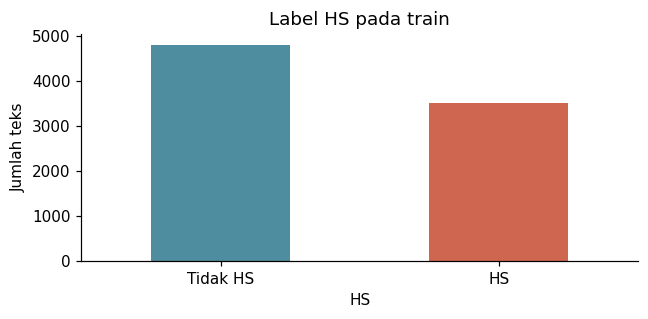

In [4]:
train, val, test = load_splits(ROOT, "02_hate_speech")
display(summarize_splits(train, val, test))
display(pd.crosstab(train.HS, train.Abusive, rownames=["HS"], colnames=["Abusive"]))
for hs, abusive in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    example = train.loc[train.HS.eq(hs) & train.Abusive.eq(abusive), ["content", "HS", "Abusive"]].head(1)
    display(example)
assert train.label.equals(train.HS)
fig, ax = plt.subplots(figsize=(6, 3))
train.HS.value_counts().sort_index().rename(index={0:"Tidak HS",1:"HS"}).plot.bar(ax=ax,color=["#4e8d9f","#cf664f"])
ax.set(title="Label HS pada train", ylabel="Jumlah teks"); ax.tick_params(axis="x",rotation=0)
fig.tight_layout(); plt.show(); plt.close(fig)

## 3. Latih satu model dan baseline · 10 menit

Kosakata dipelajari hanya dari teks train. Pipeline tidak membaca sublabel. Kita memakai `class_weight='balanced'` untuk memberi perhatian pada kelas yang lebih sedikit, lalu memeriksa dampaknya di validation. Ini tidak mengubah data test.


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.dummy import DummyClassifier

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000)),
    ("classifier", LogisticRegression(C=2.0, class_weight="balanced", max_iter=500, random_state=SEED))])
model.fit(train.content_cleaned, train.label)
positive_index = list(model.classes_).index(1)
val_probability = model.predict_proba(val.content_cleaned)[:, positive_index]
baseline = DummyClassifier(strategy="most_frequent").fit(train.content_cleaned, train.label)
print("Model selesai belajar dari", len(train), "teks, tanpa kolom label lain sebagai fitur.")

Model selesai belajar dari 8314 teks, tanpa kolom label lain sebagai fitur.


## 4. Memilih ambang sebelum membuka test · 8 menit

Model menghasilkan skor antara0 dan 1. Di atas ambang, teks ditandai untuk pemeriksaan. Menurunkan ambang biasanya menemukan lebih banyak HS, sekaligus menambah salah tandai. Skor ini belum diuji kalibrasinya dan tidak boleh dibaca sebagai probabilitas pelanggaran hukum.

Kebijakan latihan: pilih F1 kelas HS tertinggi di validation; jika seri, utamakan precision lalu ambang lebih tinggi. Kebijakan operasional sesungguhnya harus mempertimbangkan biaya kesalahan dan kapasitas pemeriksa.


In [6]:
# Fungsi yang dipakai pada langkah berikut.
def threshold_table(y_true,probabilities,thresholds=None):
    if thresholds is None:thresholds=np.round(np.arange(.2,.81,.05),2)
    return pd.DataFrame([{'threshold':float(t),
        'precision':precision_score(y_true,np.asarray(probabilities)>=t,zero_division=0),
        'recall':recall_score(y_true,np.asarray(probabilities)>=t,zero_division=0),
        'f1':f1_score(y_true,np.asarray(probabilities)>=t,zero_division=0)} for t in thresholds])

def select_threshold(validation_table):
    # Tie -> higher threshold, explicit conservative tie policy.
    return float(validation_table.sort_values(['f1','precision','threshold'],ascending=False).iloc[0]['threshold'])

,threshold,precision,recall,f1
0,0.20,0.559,0.985,0.713
1,0.25,0.598,0.966,0.738
2,0.30,0.646,0.948,0.768
3,0.35,0.696,0.921,0.793
4,0.40,0.742,0.900,0.813
5,0.45,0.785,0.872,0.826
6,0.50,0.812,0.828,0.820
7,0.55,0.842,0.767,0.803
8,0.60,0.866,0.713,0.782
9,0.65,0.888,0.662,0.759


Ambang terpilih dari validation: 0.45


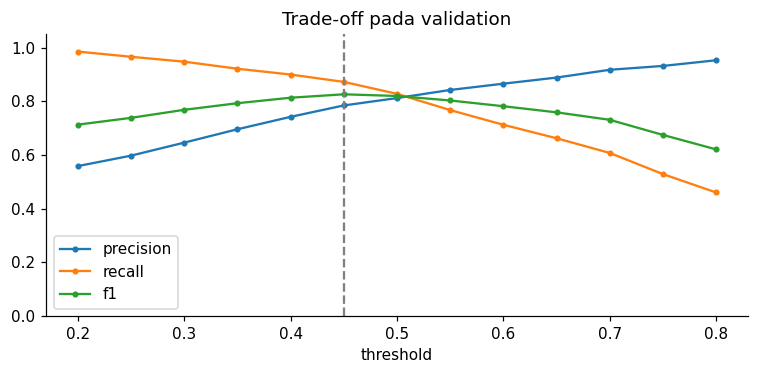

In [7]:
sweep = threshold_table(val.label, val_probability)
THRESHOLD = select_threshold(sweep)
display(sweep.round(3))
print("Ambang terpilih dari validation:", THRESHOLD)
fig, ax = plt.subplots(figsize=(7, 3.5))
sweep.plot(x="threshold", y=["precision", "recall", "f1"], ax=ax, marker=".")
ax.axvline(THRESHOLD, color="grey", linestyle="--"); ax.set(title="Trade-off pada validation", ylim=(0,1.05))
fig.tight_layout(); fig.savefig(OUT / "threshold_validation.png", dpi=150); plt.show(); plt.close(fig)

## 5. Pemeriksaan akhir pada test · 10 menit

Sekarang ambang dikunci. **False positive:** label0ditandai1. **False negative:** label1lolos sebagai0. Baca beberapa contoh setiap jenis; perbedaan dengan label sumber belum tentu berarti keputusan sumber selalu benar. Catat konteks yang tidak tersedia.


In [8]:
# Fungsi yang dipakai pada langkah berikut.
def evaluate_classification(y_true,y_pred,labels,title,output_dir):
    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)
    report=pd.DataFrame(classification_report(y_true,y_pred,labels=labels,output_dict=True,zero_division=0)).T
    fig,ax=plt.subplots(figsize=(6.4,4.8))
    ConfusionMatrixDisplay(confusion_matrix(y_true,y_pred,labels=labels),display_labels=labels).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(title);fig.tight_layout();fig.savefig(output_dir/'confusion_matrix.png',dpi=150);plt.show();plt.close(fig)
    report.to_csv(output_dir/'classification_report.csv')
    return report

def save_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding='utf-8')

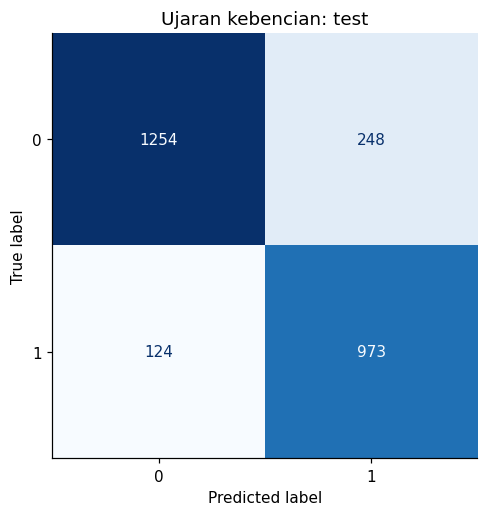

,precision,recall,f1-score,support
0,0.910,0.835,0.871,1502.000
1,0.797,0.887,0.840,1097.000
accuracy,0.857,0.857,0.857,0.857
macro avg,0.853,0.861,0.855,2599.000
weighted avg,0.862,0.857,0.858,2599.000


,model,macro_f1
0,Selalu mayoritas,0.366252
1,TF-IDF + LR,0.855175


False positive — perlu cek konteks:


,id,content,label,Abusive,prediksi,skor_HS
17,HS-03180,"Mereka yg berteriak dan mnakuti rakyat dgn mnyebut presiden lama bisa jd 2 periode kalau lawannya prabowo, itu ...",0,0,1,0.619842
33,HS-07949,USER Tolong dong orang bego gak usah dikasih lapak min',0,1,1,0.688202
46,HS-04341,USER USER Si lucinta lunaa El si banci tp geulis da oplas',0,1,1,0.888565
56,HS-11872,Terus dia manggil anaknya buat ambil duitnya di tempat si bapak itu nunggu. Baru deh duitnya dikasih ke gw. Pad...,0,0,1,0.606046


False negative — perlu cek konteks:


,id,content,label,Abusive,prediksi,skor_HS
7,HS-10935,USER USER Kasih pantun ; ? ?; -Permata dipoles menjadi batu yang indah...; -Burung srigunting memelas hati pak ...,1,0,0,0.339911
12,HS-07110,28. Anak mcd ga ada yg bener anjir\n\nBobrok\nIdiot\nKampung\nMalu maluin\nNgegas\n\nTapi kusayang karna mereka...,1,1,0,0.133373
15,HS-00448,USER Tanya amin rais.. Dulu dia yg bikin kacau dan nyuruh reformasi. Pilkada salah satu hasilnya.,1,0,0,0.232633
20,HS-02331,USER USER USER Makasih aku memang unik ga kaya armeries udik',1,1,0,0.337464


In [9]:
test_probability = model.predict_proba(test.content_cleaned)[:, positive_index]
test_prediction = (test_probability >= THRESHOLD).astype(int)
report = evaluate_classification(test.label, test_prediction, [0,1], "Ujaran kebencian: test", OUT)
display(report.round(3))
display(pd.DataFrame([
    {"model":"Selalu mayoritas", "macro_f1":f1_score(test.label, baseline.predict(test.content_cleaned), average="macro")},
    {"model":"TF-IDF + LR", "macro_f1":f1_score(test.label, test_prediction, average="macro")}]))
results = test[["id","content","label","Abusive"]].copy()
results["prediksi"] = test_prediction; results["skor_HS"] = test_probability
print("False positive — perlu cek konteks:")
display(results.query("label == 0 and prediksi == 1").head(4))
print("False negative — perlu cek konteks:")
display(results.query("label == 1 and prediksi == 0").head(4))
results.to_csv(OUT / "test_predictions.csv", index=False)
save_json(OUT / "metrics.json", {"threshold":THRESHOLD,"test_macro_f1":float(f1_score(test.label,test_prediction,average="macro")),
    "hs_precision":float(precision_score(test.label,test_prediction)),"hs_recall":float(recall_score(test.label,test_prediction))})

## 6. Keluaran multilabel dan kritik layanan · 9 menit

Kita menambah dua keluaran **independen**: HS dan Abusive. Setiap label memiliki classifier sendiri. Ini demonstrasi multilabel, bukan sistem yang sudah menjamin konsistensi semua subkategori. Jangan menjumlahkan jumlah sublabel sebagai jumlah teks unik.


In [10]:
# Fungsi yang dipakai pada langkah berikut.
def clean_text(text):
    """Same transformation used to prepare the classification datasets."""
    text=unicodedata.normalize('NFKC',str(text))
    text=re.sub(r'https?://\S+|www\.\S+','[URL]',text)
    text=re.sub(r'@[\w]+','[AKUN]',text)
    return ' '.join(text.split())

In [11]:
from sklearn.multiclass import OneVsRestClassifier
LABEL_COLUMNS = ["HS", "Abusive"]
multi = OneVsRestClassifier(LogisticRegression(C=2.0, class_weight="balanced", max_iter=500, random_state=SEED))
X_train = model.named_steps["tfidf"].transform(train.content_cleaned)
X_val = model.named_steps["tfidf"].transform(val.content_cleaned)
multi.fit(X_train, train[LABEL_COLUMNS])
val_multi_probability = multi.predict_proba(X_val)
multi_thresholds = [select_threshold(threshold_table(val[k], val_multi_probability[:,j])) for j,k in enumerate(LABEL_COLUMNS)]
multi_prediction = (multi.predict_proba(model.named_steps["tfidf"].transform(test.content_cleaned)) >= multi_thresholds).astype(int)
display(pd.DataFrame([{ "label":k,"threshold":multi_thresholds[j],
    "f1":f1_score(test[k],multi_prediction[:,j],zero_division=0)} for j,k in enumerate(LABEL_COLUMNS)]))

# Semua kalimat berikut sintetis. Label di bawah ini adalah ekspektasi diskusi, bukan gold riset.
challenge = pd.DataFrame({"content":[
    "Pelayanan SIM lambat, saya kecewa dan meminta perbaikan antrean.",
    "Informasi biaya SKCK perlu dipasang lebih jelas di loket.",
    "Terima kasih petugas yang membantu warga menyeberang.",
    "Berita ini mengecam ajakan mengusir warga berdasarkan asal kelompoknya."],
    "catatan":["kritik layanan","kritik layanan","apresiasi","laporan atau kutipan, konteks penting"]})
challenge["skor_HS"] = model.predict_proba(challenge.content.map(clean_text))[:,positive_index]
challenge["ditandai"] = challenge.skor_HS.ge(THRESHOLD)
display(challenge)

,label,threshold,f1
0,HS,0.45,0.839517
1,Abusive,0.60,0.858496


,content,catatan,skor_HS,ditandai
0,"Pelayanan SIM lambat, saya kecewa dan meminta perbaikan antrean.",kritik layanan,0.192304,False
1,Informasi biaya SKCK perlu dipasang lebih jelas di loket.,kritik layanan,0.316543,False
2,Terima kasih petugas yang membantu warga menyeberang.,apresiasi,0.115398,False
3,Berita ini mengecam ajakan mengusir warga berdasarkan asal kelompoknya.,"laporan atau kutipan, konteks penting",0.288640,False


### Tugas peserta dan penutup

- Bandingkan precision/recall **validation** pada ambang0,35 dan 0,70. Mana yang membebani pemeriksa lebih banyak?
- Ambil satu false positive dan tulis informasi tambahan yang perlu dibaca manusia sebelum bertindak.
- Apakah kritik layanan dalam contoh ditandai model? Jika ya, apa risikonya?

**Batas hasil:** domain 2019, slang berubah, anotasi dapat berbeda, konteks percakapan hilang, dan skor bukan bukti. Pelaporan F1 tidak mengukur kemampuan mencegah kerusuhan. Model tidak mengirim laporan, menghapus konten, atau mengambil tindakan terhadap akun.

Sumber: [Ibrohim & Budi 2019](https://aclanthology.org/W19-3506/), [dataset asli](https://github.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection), [threshold tuning scikit-learn](https://scikit-learn.org/stable/modules/classification_threshold.html). **Lisensi dataset CC BY-NC-SA4.0**, lihat `dataset/README.md` sebelum penggunaan komersial.
